Reading: USGS | HBV | Single
Reading: USGS | HBV_capillary | Single
Reading: USGS | marrmot_PRMS | Single
Reading: Furey | HBV | Single
Reading: Furey | HBV_capillary | Single
Reading: Furey | marrmot_PRMS | Single
Reading: Eckhardt | HBV | Single
Reading: Eckhardt | HBV_capillary | Single
Reading: Eckhardt | marrmot_PRMS | Single
Reading: LocalHYSEP | HBV | Single
Reading: LocalHYSEP | HBV_capillary | Single
Reading: LocalHYSEP | marrmot_PRMS | Single
Reading: USGS | HBV | Multi
Reading: USGS | HBV_capillary | Multi
Reading: USGS | marrmot_PRMS | Multi
Reading: Furey | HBV | Multi
Reading: Furey | HBV_capillary | Multi
Reading: Furey | marrmot_PRMS | Multi
Reading: Eckhardt | HBV | Multi
Reading: Eckhardt | HBV_capillary | Multi
Reading: Eckhardt | marrmot_PRMS | Multi
Reading: LocalHYSEP | HBV | Multi
Reading: LocalHYSEP | HBV_capillary | Multi
Reading: LocalHYSEP | marrmot_PRMS | Multi

NSE SUMMARY
Single: N = 6372, Median = 0.6971, Mean = 0.4997
Multi : N = 6372, Median = 0.6918, M

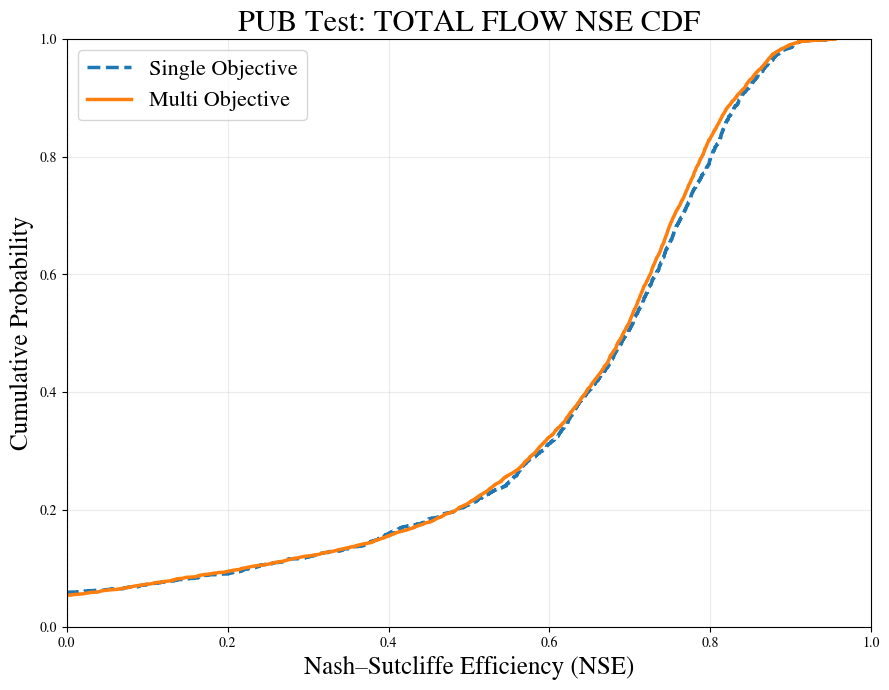

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

plt.rcParams['font.family']= 'Nimbus Roman'
# ============================================================
# SETTINGS
# ============================================================

test = 'PUB'

methods = [
    'USGS',
    'Furey',
    'Eckhardt',
    'LocalHYSEP'
]

models = [
    'HBV',
    'HBV_capillary',
    'marrmot_PRMS'
]

objectives = [
    'Single',
    'Multi'
]


# ============================================================
# 10 PUB FOLDS
# ============================================================

fold_numbers = range(1, 11)


# ============================================================
# DYNAMIC PARAMETER FOLDER
# ============================================================

def get_dyn(model):

    if model == 'HBV':
        return 'parBETA_parBETAET_'

    elif model == 'HBV_capillary':
        return 'parBETA_parBETAET_parK0_parUZL_'

    elif model == 'marrmot_PRMS':
        return 'alpha_cgw_scx_tt_'

    else:
        raise ValueError(f"Unknown model: {model}")


# ============================================================
# NSE FUNCTION
# ============================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    denominator = np.sum(
        (obs - np.mean(obs)) ** 2
    )

    if denominator == 0:
        return np.nan

    numerator = np.sum(
        (obs - sim) ** 2
    )

    return 1 - numerator / denominator


# ============================================================
# GET NSE VALUES
# ============================================================

def get_all_nse(objective):

    all_nse = []

    # --------------------------------------------------------
    # Loop over methods
    # --------------------------------------------------------

    for method in methods:

        # ----------------------------------------------------
        # Loop over models
        # ----------------------------------------------------

        for model in models:

            dyn = get_dyn(model)

            print(
                f"Reading: "
                f"{method} | {model} | {objective}"
            )

            # ------------------------------------------------
            # Loop over 10 folds
            # ------------------------------------------------

            for i in fold_numbers:

                # ============================================
                # FOLDER
                # ============================================

                if objective == 'Multi':

                    folder = (
                        f"/home/s0shar47/scratch/"
                        f"OUTPUTS_Paper1/{test}/"
                        f"{method}_Multi/{i}/"
                    )

                elif objective == 'Single':

                    folder = (
                        f"/home/s0shar47/scratch/"
                        f"OUTPUTS_Paper1/{test}/"
                        f"OUTPUTS_PUB_Single/{i}/"
                    )


                # ============================================
                # RUN FOLDER
                # ============================================

                run_folder = (
                    f"LSTM_{model}_E50_R365_B100_H256_"
                    f"tr1989_1999_n16_111111"
                )


                # ============================================
                # OBSERVED FLOW
                # ============================================

                obs_file = os.path.join(
                    folder,
                    run_folder,
                    dyn,
                    "ts1989_1999",
                    "00060_Mean.npy"
                    # "baseflow.npy"
                )


                # ============================================
                # SIMULATED FLOW
                # ============================================

                sim_file = os.path.join(
                    folder,
                    run_folder,
                    dyn,
                    "ts1989_1999",
                    "flow_sim.npy"
                    # "gwflow.npy"
                )


                # ============================================
                # CHECK FILES
                # ============================================

                if not os.path.exists(obs_file):

                    print(
                        f"  Missing OBS: "
                        f"{method}, {model}, fold {i}"
                    )

                    continue


                if not os.path.exists(sim_file):

                    print(
                        f"  Missing SIM: "
                        f"{method}, {model}, fold {i}"
                    )

                    continue


                # ============================================
                # LOAD
                # ============================================

                obs_flow = np.squeeze(
                    np.load(obs_file)
                )

                sim_flow = np.squeeze(
                    np.load(sim_file)
                )


                # ============================================
                # SHAPE CHECK
                # ============================================

                if obs_flow.shape != sim_flow.shape:

                    print(
                        f"  Shape mismatch: "
                        f"{method}, {model}, fold {i}"
                    )

                    continue


                # ============================================
                # BASIN-WISE NSE
                # ============================================

                for basin in range(
                    obs_flow.shape[1]
                ):

                    obs = obs_flow[:, basin]
                    sim = sim_flow[:, basin]

                    nse = calc_nse(
                        obs,
                        sim
                    )

                    if np.isfinite(nse):

                        all_nse.append(nse)


    return np.asarray(
        all_nse,
        dtype=float
    )


# ============================================================
# LOAD SINGLE AND MULTI NSE
# ============================================================

nse_single = get_all_nse(
    objective='Single'
)

nse_multi = get_all_nse(
    objective='Multi'
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("NSE SUMMARY")
print("=" * 70)

print(
    f"Single: "
    f"N = {len(nse_single)}, "
    f"Median = {np.nanmedian(nse_single):.4f}, "
    f"Mean = {np.nanmean(nse_single):.4f}"
)

print(
    f"Multi : "
    f"N = {len(nse_multi)}, "
    f"Median = {np.nanmedian(nse_multi):.4f}, "
    f"Mean = {np.nanmean(nse_multi):.4f}"
)


# ============================================================
# EMPIRICAL CDF
# ============================================================

def empirical_cdf(values):

    values = values[
        np.isfinite(values)
    ]

    values = np.sort(values)

    y = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    return values, y


x_single, y_single = empirical_cdf(
    nse_single
)

x_multi, y_multi = empirical_cdf(
    nse_multi
)


# ============================================================
# PLOT CDF
# ============================================================

plt.figure(
    figsize=(9, 7)
)


# ------------------------------------------------------------
# Single
# ------------------------------------------------------------

plt.plot(
    x_single,
    y_single,
    linewidth=2.5,
    linestyle='--',
    label='Single Objective'
)


# ------------------------------------------------------------
# Multi
# ------------------------------------------------------------

plt.plot(
    x_multi,
    y_multi,
    linewidth=2.5,
    linestyle='-',
    label='Multi Objective'
)


# ============================================================
# REFERENCE LINE
# ============================================================

plt.axvline(
    x=0,
    linestyle=':',
    linewidth=1.5
)


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel(
    'Nash–Sutcliffe Efficiency (NSE)',
    fontsize=18
)

plt.ylabel(
    'Cumulative Probability',
    fontsize=18
)


# ============================================================
# TITLE
# ============================================================

plt.title(
    'PUB Test: TOTAL FLOW NSE CDF',
    fontsize=22
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    True,
    alpha=0.25
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    fontsize=16,
    frameon=True
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SHOW
# ============================================================

plt.show()

Reading: USGS | HBV | Single
Reading: USGS | HBV_capillary | Single
Reading: USGS | marrmot_PRMS | Single
Reading: Furey | HBV | Single
Reading: Furey | HBV_capillary | Single
Reading: Furey | marrmot_PRMS | Single
Reading: Eckhardt | HBV | Single
Reading: Eckhardt | HBV_capillary | Single
Reading: Eckhardt | marrmot_PRMS | Single
Reading: LocalHYSEP | HBV | Single
Reading: LocalHYSEP | HBV_capillary | Single
Reading: LocalHYSEP | marrmot_PRMS | Single
Reading: USGS | HBV | Multi
Reading: USGS | HBV_capillary | Multi
Reading: USGS | marrmot_PRMS | Multi
Reading: Furey | HBV | Multi
Reading: Furey | HBV_capillary | Multi
Reading: Furey | marrmot_PRMS | Multi
Reading: Eckhardt | HBV | Multi
Reading: Eckhardt | HBV_capillary | Multi
Reading: Eckhardt | marrmot_PRMS | Multi
Reading: LocalHYSEP | HBV | Multi
Reading: LocalHYSEP | HBV_capillary | Multi
Reading: LocalHYSEP | marrmot_PRMS | Multi

NSE SUMMARY
Single: N = 6369, Median = 0.3947, Mean = -332768604.3881
Multi : N = 6369, Median = 

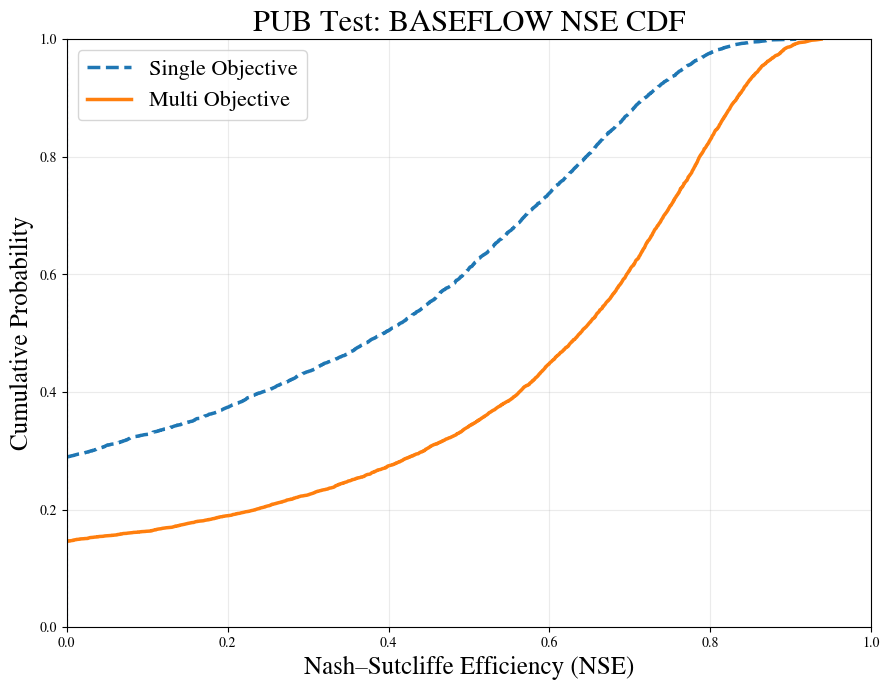

In [3]:
import numpy as np
import os
import matplotlib.pyplot as plt

plt.rcParams['font.family']= 'Nimbus Roman'
# ============================================================
# SETTINGS
# ============================================================

test = 'PUB'

methods = [
    'USGS',
    'Furey',
    'Eckhardt',
    'LocalHYSEP'
]

models = [
    'HBV',
    'HBV_capillary',
    'marrmot_PRMS'
]

objectives = [
    'Single',
    'Multi'
]


# ============================================================
# 10 PUB FOLDS
# ============================================================

fold_numbers = range(1, 11)


# ============================================================
# DYNAMIC PARAMETER FOLDER
# ============================================================

def get_dyn(model):

    if model == 'HBV':
        return 'parBETA_parBETAET_'

    elif model == 'HBV_capillary':
        return 'parBETA_parBETAET_parK0_parUZL_'

    elif model == 'marrmot_PRMS':
        return 'alpha_cgw_scx_tt_'

    else:
        raise ValueError(f"Unknown model: {model}")


# ============================================================
# NSE FUNCTION
# ============================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    denominator = np.sum(
        (obs - np.mean(obs)) ** 2
    )

    if denominator == 0:
        return np.nan

    numerator = np.sum(
        (obs - sim) ** 2
    )

    return 1 - numerator / denominator


# ============================================================
# GET NSE VALUES
# ============================================================

def get_all_nse(objective):

    all_nse = []

    # --------------------------------------------------------
    # Loop over methods
    # --------------------------------------------------------

    for method in methods:

        # ----------------------------------------------------
        # Loop over models
        # ----------------------------------------------------

        for model in models:

            dyn = get_dyn(model)

            print(
                f"Reading: "
                f"{method} | {model} | {objective}"
            )

            # ------------------------------------------------
            # Loop over 10 folds
            # ------------------------------------------------

            for i in fold_numbers:

                # ============================================
                # FOLDER
                # ============================================

                if objective == 'Multi':

                    ofolder = (
                        f"/home/s0shar47/scratch/"
                        f"OUTPUTS_Paper1/PUB/"
                        f"{method}_Multi/{i}/"
                        )

                    folder = (
                        f"/home/s0shar47/scratch/"
                        f"OUTPUTS_Paper1/PUB/"
                        f"{method}_Multi/{i}/"
                    )

                elif objective == 'Single':
                    ofolder = (
                            f"/home/s0shar47/scratch/"
                            f"OUTPUTS_Paper1/PUB/"
                            f"{method}_Multi/{i}/"
                                )
                    folder = (
                        f"/home/s0shar47/scratch/"
                        f"OUTPUTS_Paper1/PUB/"
                        f"OUTPUTS_PUB_Single/{i}/"
                    )


                # ============================================
                # RUN FOLDER
                # ============================================

                run_folder = (
                    f"LSTM_{model}_E50_R365_B100_H256_"
                    f"tr1989_1999_n16_111111"
                )


                # ============================================
                # OBSERVED FLOW
                # ============================================

                obs_file = os.path.join(
                    ofolder,
                    run_folder,
                    dyn,
                    "ts1989_1999",
                    "baseflow.npy"
                )


                # ============================================
                # SIMULATED FLOW
                # ============================================

                sim_file = os.path.join(
                    folder,
                    run_folder,
                    dyn,
                    "ts1989_1999",
                    "gwflow.npy"
                )


                # ============================================
                # CHECK FILES
                # ============================================

                if not os.path.exists(obs_file):

                    print(
                        f"  Missing OBS: "
                        f"{method}, {model}, fold {i}"
                    )

                    continue


                if not os.path.exists(sim_file):

                    print(
                        f"  Missing SIM: "
                        f"{method}, {model}, fold {i}"
                    )

                    continue


                # ============================================
                # LOAD
                # ============================================

                obs_flow = np.squeeze(
                    np.load(obs_file)
                )

                sim_flow = np.squeeze(
                    np.load(sim_file)
                )


                # ============================================
                # SHAPE CHECK
                # ============================================

                if obs_flow.shape != sim_flow.shape:

                    print(
                        f"  Shape mismatch: "
                        f"{method}, {model}, fold {i}"
                    )

                    continue


                # ============================================
                # BASIN-WISE NSE
                # ============================================

                for basin in range(
                    obs_flow.shape[1]
                ):

                    obs = obs_flow[:, basin]
                    sim = sim_flow[:, basin]

                    nse = calc_nse(
                        obs,
                        sim
                    )

                    if np.isfinite(nse):

                        all_nse.append(nse)


    return np.asarray(
        all_nse,
        dtype=float
    )


# ============================================================
# LOAD SINGLE AND MULTI NSE
# ============================================================

nse_single = get_all_nse(
    objective='Single'
)

nse_multi = get_all_nse(
    objective='Multi'
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("NSE SUMMARY")
print("=" * 70)

print(
    f"Single: "
    f"N = {len(nse_single)}, "
    f"Median = {np.nanmedian(nse_single):.4f}, "
    f"Mean = {np.nanmean(nse_single):.4f}"
)

print(
    f"Multi : "
    f"N = {len(nse_multi)}, "
    f"Median = {np.nanmedian(nse_multi):.4f}, "
    f"Mean = {np.nanmean(nse_multi):.4f}"
)


# ============================================================
# EMPIRICAL CDF
# ============================================================

def empirical_cdf(values):

    values = values[
        np.isfinite(values)
    ]

    values = np.sort(values)

    y = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    return values, y


x_single, y_single = empirical_cdf(
    nse_single
)

x_multi, y_multi = empirical_cdf(
    nse_multi
)


# ============================================================
# PLOT CDF
# ============================================================

plt.figure(
    figsize=(9, 7)
)


# ------------------------------------------------------------
# Single
# ------------------------------------------------------------

plt.plot(
    x_single,
    y_single,
    linewidth=2.5,
    linestyle='--',
    label='Single Objective'
)


# ------------------------------------------------------------
# Multi
# ------------------------------------------------------------

plt.plot(
    x_multi,
    y_multi,
    linewidth=2.5,
    linestyle='-',
    label='Multi Objective'
)


# ============================================================
# REFERENCE LINE
# ============================================================

plt.axvline(
    x=0,
    linestyle=':',
    linewidth=1.5
)


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel(
    'Nash–Sutcliffe Efficiency (NSE)',
    fontsize=18
)

plt.ylabel(
    'Cumulative Probability',
    fontsize=18
)


# ============================================================
# TITLE
# ============================================================

plt.title(
    'PUB Test: BASEFLOW NSE CDF',
    fontsize=22
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    True,
    alpha=0.25
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    fontsize=16,
    frameon=True
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SHOW
# ============================================================

plt.show()


LOADING FLOW | SINGLE OBJECTIVE
Reading: USGS | HBV | flow | Single
Reading: USGS | HBV_capillary | flow | Single
Reading: USGS | marrmot_PRMS | flow | Single
Reading: Furey | HBV | flow | Single
Reading: Furey | HBV_capillary | flow | Single
Reading: Furey | marrmot_PRMS | flow | Single
Reading: Eckhardt | HBV | flow | Single
Reading: Eckhardt | HBV_capillary | flow | Single
Reading: Eckhardt | marrmot_PRMS | flow | Single
Reading: LocalHYSEP | HBV | flow | Single
Reading: LocalHYSEP | HBV_capillary | flow | Single
Reading: LocalHYSEP | marrmot_PRMS | flow | Single

LOADING FLOW | MULTI OBJECTIVE
Reading: USGS | HBV | flow | Multi
Reading: USGS | HBV_capillary | flow | Multi
Reading: USGS | marrmot_PRMS | flow | Multi
Reading: Furey | HBV | flow | Multi
Reading: Furey | HBV_capillary | flow | Multi
Reading: Furey | marrmot_PRMS | flow | Multi
Reading: Eckhardt | HBV | flow | Multi
Reading: Eckhardt | HBV_capillary | flow | Multi
Reading: Eckhardt | marrmot_PRMS | flow | Multi
Reading

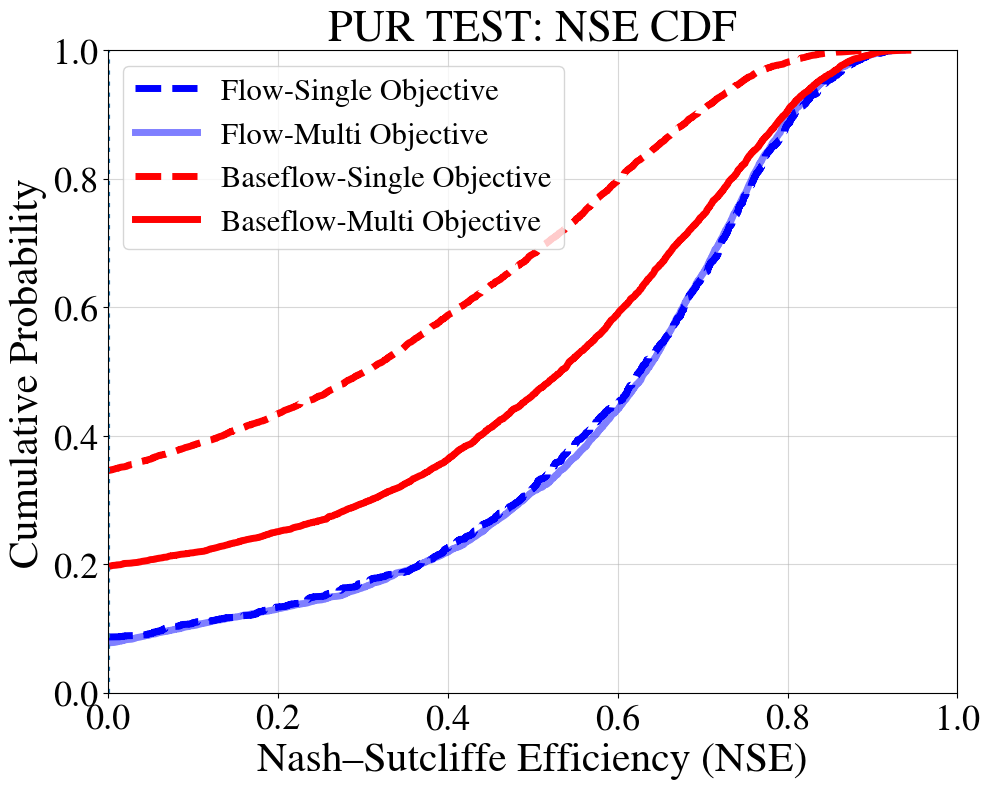

In [9]:
import numpy as np
import os
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Nimbus Roman'


# ============================================================
# SETTINGS
# ============================================================
test= 'PUR'
methods = [
    'USGS',
    'Furey',
    'Eckhardt',
    'LocalHYSEP'
]

models = [
    'HBV',
    'HBV_capillary',
    'marrmot_PRMS'
]

fold_numbers = range(1, 8)


# ============================================================
# PUB BASE DIRECTORY
# ============================================================

BASE_DIR = (
    "/home/s0shar47/scratch/"
    f"OUTPUTS_Paper1/{test}"
)


# ============================================================
# DYNAMIC PARAMETER FOLDER
# ============================================================

def get_dyn(model):

    if model == 'HBV':
        return 'parBETA_parBETAET_'

    elif model == 'HBV_capillary':
        return 'parBETA_parBETAET_parK0_parUZL_'

    elif model == 'marrmot_PRMS':
        return 'alpha_cgw_scx_tt_'

    else:
        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# NSE
# ============================================================

def calc_nse(obs, sim):

    mask = (
        np.isfinite(obs)
        &
        np.isfinite(sim)
    )

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    denominator = np.sum(
        (obs - np.mean(obs)) ** 2
    )

    if denominator == 0:
        return np.nan

    numerator = np.sum(
        (obs - sim) ** 2
    )

    return 1 - numerator / denominator


# ============================================================
# GET NSE
#
# component:
#     flow
#     baseflow
#
# objective:
#     Single
#     Multi
# ============================================================

def get_all_nse(component, objective):

    all_nse = []

    print("\n" + "=" * 80)
    print(
        f"LOADING {component.upper()} | "
        f"{objective.upper()} OBJECTIVE"
    )
    print("=" * 80)

    # ========================================================
    # LOOP METHODS
    # ========================================================

    for method in methods:

        # ====================================================
        # LOOP MODELS
        # ====================================================

        for model in models:

            dyn = get_dyn(model)

            print(
                f"Reading: {method} | "
                f"{model} | "
                f"{component} | "
                f"{objective}"
            )

            # =================================================
            # LOOP 10 PUB FOLDS
            # =================================================

            for fold in fold_numbers:

                region = f'Region_{fold}'

                # ====================================================
                # FOLDER DEFINITIONS
                # ====================================================

                single_folder = os.path.join(
                    BASE_DIR,
                    f"OUTPUTS_{test}_Single",
                    region
                )

                multi_folder = os.path.join(
                    BASE_DIR,
                    f"{method}_Multi",
                    region
                )


                # ====================================================
                # SIMULATION FOLDER
                # ====================================================

                if objective == 'Single':

                    simulation_folder = (
                        single_folder
                    )

                elif objective == 'Multi':

                    simulation_folder = (
                        multi_folder
                    )

                else:

                    raise ValueError(
                        f"Unknown objective: {objective}"
                    )


                # ====================================================
                # RUN FOLDER
                # ====================================================

                run_folder = (
                    f"LSTM_{model}_E50_R365_B100_H256_"
                    f"tr1989_1999_n16_111111"
                )


                # ====================================================
                # BASE RUN DIRECTORY
                # ====================================================

                run_dir = os.path.join(
                    run_folder,
                    dyn,
                    "ts1989_1999"
                )


                # ====================================================
                # FLOW
                # ====================================================

                if component == 'flow':

                    obs_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "00060_Mean.npy"
                    )

                    sim_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "flow_sim.npy"
                    )


                # ====================================================
                # BASEFLOW
                # ====================================================

                elif component == 'baseflow':

                    # ------------------------------------------------
                    # IMPORTANT:
                    #
                    # Observed baseflow ALWAYS comes from Multi
                    # because Single does not contain baseflow.npy.
                    # ------------------------------------------------

                    obs_file = os.path.join(
                        multi_folder,
                        run_dir,
                        "baseflow.npy"
                    )

                    # ------------------------------------------------
                    # Simulated groundwater flow depends on objective
                    # ------------------------------------------------

                    sim_file = os.path.join(
                        simulation_folder,
                        run_dir,
                        "gwflow.npy"
                    )


                else:

                    raise ValueError(
                        f"Unknown component: {component}"
                    )


                # ====================================================
                # CHECK FILES
                # ====================================================

                if not os.path.exists(obs_file):

                    print(
                        f"  Missing OBS: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  --> {obs_file}"
                    )

                    continue


                if not os.path.exists(sim_file):

                    print(
                        f"  Missing SIM: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  --> {sim_file}"
                    )

                    continue


                # ====================================================
                # LOAD
                # ====================================================

                obs = np.load(obs_file)
                sim = np.load(sim_file)

                obs = np.squeeze(obs)
                sim = np.squeeze(sim)


                # ====================================================
                # SHAPE CHECK
                # ====================================================

                if obs.shape != sim.shape:

                    print(
                        f"  Shape mismatch: "
                        f"{method}, {model}, "
                        f"{component}, {objective}, "
                        f"fold {fold}"
                    )

                    print(
                        f"  OBS shape = {obs.shape}"
                    )

                    print(
                        f"  SIM shape = {sim.shape}"
                    )

                    continue


                # ====================================================
                # BASIN-WISE NSE
                # ====================================================

                for basin in range(
                    obs.shape[1]
                ):

                    obs_basin = obs[:, basin]

                    sim_basin = sim[:, basin]

                    nse = calc_nse(
                        obs_basin,
                        sim_basin
                    )

                    if np.isfinite(nse):

                        all_nse.append(nse)


    return np.asarray(
        all_nse,
        dtype=float
    )


# ============================================================
# LOAD FLOW
# ============================================================

nse_flow_single = get_all_nse(
    component='flow',
    objective='Single'
)

nse_flow_multi = get_all_nse(
    component='flow',
    objective='Multi'
)


# ============================================================
# LOAD BASEFLOW
# ============================================================

nse_baseflow_single = get_all_nse(
    component='baseflow',
    objective='Single'
)

nse_baseflow_multi = get_all_nse(
    component='baseflow',
    objective='Multi'
)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL NSE SUMMARY")
print("=" * 80)

def print_summary(name, values):

    if len(values) == 0:

        print(
            f"{name:25s}: N = 0"
        )

    else:

        print(
            f"{name:25s}: "
            f"N = {len(values):5d}, "
            f"Median = {np.median(values):.4f}, "
            f"Mean = {np.mean(values):.4f}"
        )


print_summary(
    "Flow - Single",
    nse_flow_single
)

print_summary(
    "Flow - Multi",
    nse_flow_multi
)

print_summary(
    "Baseflow - Single",
    nse_baseflow_single
)

print_summary(
    "Baseflow - Multi",
    nse_baseflow_multi
)


# ============================================================
# EMPIRICAL CDF
# ============================================================

def empirical_cdf(values):

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:

        return (
            np.array([]),
            np.array([])
        )

    values = np.sort(values)

    y = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    return values, y


# ============================================================
# CDFS
# ============================================================

x_flow_single, y_flow_single = empirical_cdf(
    nse_flow_single
)

x_flow_multi, y_flow_multi = empirical_cdf(
    nse_flow_multi
)

x_baseflow_single, y_baseflow_single = empirical_cdf(
    nse_baseflow_single
)

x_baseflow_multi, y_baseflow_multi = empirical_cdf(
    nse_baseflow_multi
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)


# ------------------------------------------------------------
# FLOW — SINGLE
# ------------------------------------------------------------

if len(x_flow_single) > 0:

    plt.plot(
        x_flow_single,
        y_flow_single,
        linewidth=5,
        linestyle='--',
        label='Flow-Single Objective'
        ,color= 'blue'
    )


# ------------------------------------------------------------
# FLOW — MULTI
# ------------------------------------------------------------

if len(x_flow_multi) > 0:

    plt.plot(
        x_flow_multi,
        y_flow_multi,
        linewidth=5,
        linestyle='-',
        label='Flow-Multi Objective'
        ,color= 'blue',
        alpha=0.5
    )


# ------------------------------------------------------------
# BASEFLOW — SINGLE
# ------------------------------------------------------------

if len(x_baseflow_single) > 0:

    plt.plot(
        x_baseflow_single,
        y_baseflow_single,
        linewidth=5,
        linestyle='--',
        label='Baseflow-Single Objective'
        ,color= 'red'
    )


# ------------------------------------------------------------
# BASEFLOW — MULTI
# ------------------------------------------------------------

if len(x_baseflow_multi) > 0:

    plt.plot(
        x_baseflow_multi,
        y_baseflow_multi,
        linewidth=5,
        linestyle='-',
        label='Baseflow-Multi Objective'
        ,color= 'red'
    )


# ============================================================
# NSE = 0
# ============================================================

plt.axvline(
    x=0,
    linestyle=':',
    linewidth=3
)


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel(
    'Nash–Sutcliffe Efficiency (NSE)',
    fontsize=30
)

plt.ylabel(
    'Cumulative Probability',
    fontsize=30
)


# ============================================================
# TITLE
# ============================================================

plt.title(
    f'{test} TEST: NSE CDF',
    fontsize=32
)


# ============================================================
# TICKS
# ============================================================

plt.xticks(
    fontsize=26
)

plt.yticks(
    fontsize=26
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    True,
    alpha=0.5
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    fontsize=22,
    frameon=True,
    loc='upper left'
)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SHOW
# ============================================================

plt.show()